# 01 — Data Exploration

Dataset Shape: (10000, 14)

Data Types:
 UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Missing Values per Column:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplic

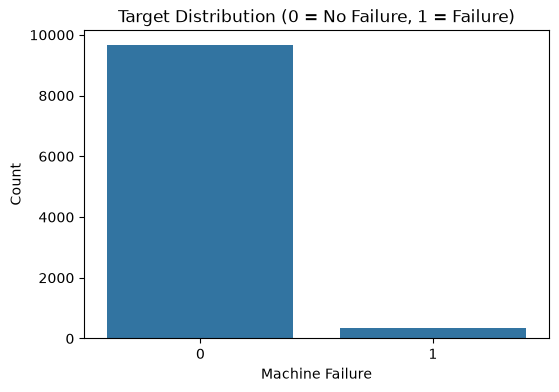


Product Type Distribution:
 Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


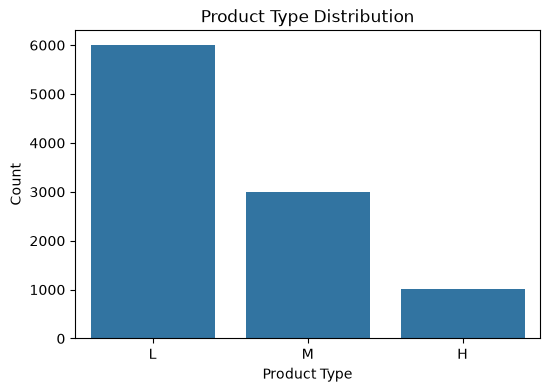


Numeric Columns Summary:
        Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
count         10000.000000             10000.000000            10000.000000   
mean            300.004930               310.005560             1538.776100   
std               2.000259                 1.483734              179.284096   
min             295.300000               305.700000             1168.000000   
25%             298.300000               308.800000             1423.000000   
50%             300.100000               310.100000             1503.000000   
75%             301.500000               311.100000             1612.000000   
max             304.500000               313.800000             2886.000000   

        Torque [Nm]  Tool wear [min]  
count  10000.000000     10000.000000  
mean      39.986910       107.951000  
std        9.968934        63.654147  
min        3.800000         0.000000  
25%       33.200000        53.000000  
50%       40.100000       1

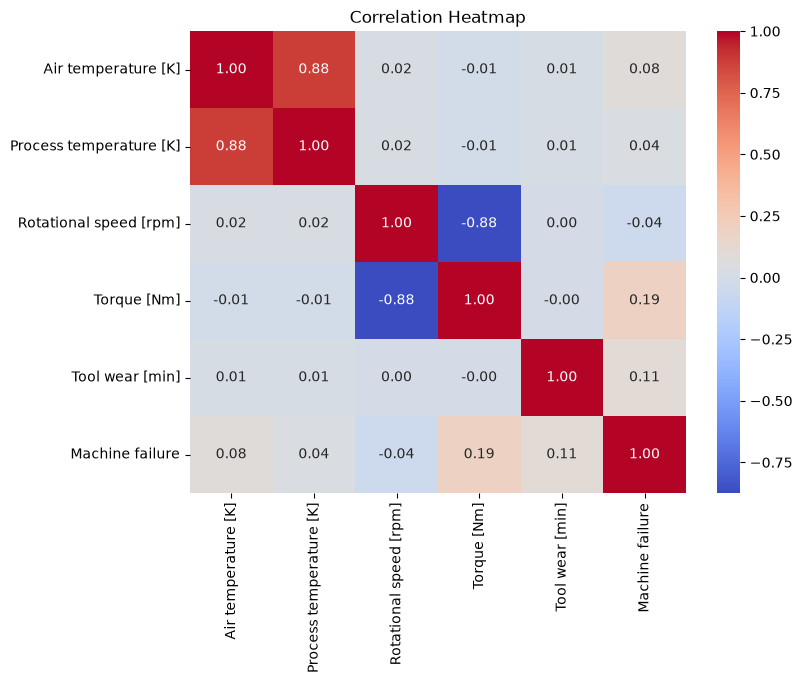

In [1]:
import os
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- Project Path Setup ---
# Determine project root reliably whether run from project root or notebooks folder
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)

RAW_FILE = PROJECT_ROOT / "data" / "raw" / "machine_failure.csv"
if not RAW_FILE.exists():
    raise FileNotFoundError(f"Raw dataset not found at '{RAW_FILE}'. Please verify the data directory.")

# 1. Load the raw dataset
df = pd.read_csv("data/raw/machine_failure.csv")

# 2. Check dataset shape and data types
print("Dataset Shape:", df.shape)
print("\nData Types:\n", df.dtypes)

# 3. Check for missing values and duplicate rows
print("\nMissing Values per Column:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

# 4. Target variable distribution (Machine failure)
print("\nTarget Distribution (Counts):\n", df["Machine failure"].value_counts())
print("\nTarget Distribution (Percentage):\n", df["Machine failure"].value_counts(normalize=True) * 100)

# Plot target distribution
plt.figure(figsize=(6, 4))
sns.countplot(x="Machine failure", data=df)
plt.title("Target Distribution (0 = No Failure, 1 = Failure)")
plt.xlabel("Machine Failure")
plt.ylabel("Count")
plt.show()

# 5. Categorical feature distribution (Product Type: L, M, H)
print("\nProduct Type Distribution:\n", df["Type"].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(x="Type", data=df, order=["L", "M", "H"])
plt.title("Product Type Distribution")
plt.xlabel("Product Type")
plt.ylabel("Count")
plt.show()

# 6. Summary statistics of the main numeric sensor columns
numeric_cols = [
    "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"
]
print("\nNumeric Columns Summary:\n", df[numeric_cols].describe())

# 7. Check for data leakage / consistency with failure sub-labels
sub_label_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]
sub_label_sum = df[sub_label_cols].sum(axis=1)

leakage_match = ((sub_label_sum > 0) == (df["Machine failure"] == 1))
print(f"\nSub-labels match target for {leakage_match.sum()} / {len(df)} rows.")
print(f"Mismatch on {(~leakage_match).sum()} rows (documented label noise in the dataset).")

# 8. Correlation between numeric features and Machine failure
corr_matrix = df[numeric_cols + ["Machine failure"]].corr()
print("\nCorrelation with Machine failure:\n", corr_matrix["Machine failure"].sort_values(ascending=False))

# Plot correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()